# Comparação de parâmetros intrínsecos — Zhang × OpenCV × ARKit

Este notebook consolida os resultados já produzidos pelos notebooks anteriores e faz, de forma automática:

1. leitura dos JSONs de **Zhang**, **OpenCV restrito**, **OpenCV padrão** e **ARKit**;
2. detecção das resoluções usadas por cada método;
3. rotação automática da matriz intrínseca do ARKit quando o stream está em *landscape* e a calibração em *portrait*;
4. redimensionamento da matriz do ARKit para a resolução das imagens usadas na calibração;
5. comparação direta de $f_x$, $f_y$, $c_x$, $c_y$ e $\gamma$;
6. diferenças absolutas e percentuais em relação ao ARKit normalizado;
7. análise da estabilidade temporal dos 120 frames do ARKit.

A comparação principal usa o **stream do ARKit** (`statistics`, 120 frames). As capturas de alta resolução, quando presentes, são tratadas apenas como verificação auxiliar e não entram na tabela principal.

In [1]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")

## 1. Localização automática do repositório

O notebook pode ser executado a partir da raiz do repositório ou de uma subpasta, por exemplo `notebooks/`.

A estrutura esperada é:

```text
results/
├── calibration/
│   ├── iphone15.json
│   └── ipad9.json
├── opencv/
│   ├── iphone15_restricted.json
│   ├── iphone15_standard.json
│   ├── ipad9_restricted.json
│   └── ipad9_standard.json
└── arkit/
    ├── arkit_intrinsics_iphone15.json
    └── arkit_intrinsics_ipad9.json
```

In [2]:
# Se necessário, defina manualmente a raiz. Caso contrário, deixe como None.
REPO_ROOT_OVERRIDE = None

def locate_repo_root(start: Path | None = None) -> Path:
    if REPO_ROOT_OVERRIDE is not None:
        root = Path(REPO_ROOT_OVERRIDE).expanduser().resolve()
        if not (root / "results").exists():
            raise FileNotFoundError(f"REPO_ROOT_OVERRIDE não contém results/: {root}")
        return root

    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]

    for candidate in candidates:
        if (candidate / "results").is_dir():
            return candidate

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do repositório automaticamente. "
        "Execute o notebook dentro do projeto ou defina REPO_ROOT_OVERRIDE."
    )

ROOT = locate_repo_root()
RESULTS = ROOT / "results"

print("Raiz do repositório:", ROOT)
print("Diretório de resultados:", RESULTS)

Raiz do repositório: /Users/gabriellopesbastos/Projects/camera-calibration-zhang
Diretório de resultados: /Users/gabriellopesbastos/Projects/camera-calibration-zhang/results


## 2. Configuração das câmeras e descoberta dos arquivos

Os nomes abaixo correspondem aos resultados já gerados para o iPhone 15 e o iPad 9. A função `resolve_json` primeiro tenta o caminho esperado e, se não encontrar, procura recursivamente pelo mesmo nome dentro de `results/`.

In [3]:
CAMERAS = {
    "iphone15": {
        "label": "iPhone 15",
        "zhang": "calibration/iphone15.json",
        "opencv_restricted": "opencv/iphone15_restricted.json",
        "opencv_standard": "opencv/iphone15_standard.json",
        "arkit": "arkit/arkit_intrinsics_iphone15.json",
    },
    "ipad9": {
        "label": "iPad 9",
        "zhang": "calibration/ipad9.json",
        "opencv_restricted": "opencv/ipad9_restricted.json",
        "opencv_standard": "opencv/ipad9_standard.json",
        "arkit": "arkit/arkit_intrinsics_ipad9.json",
    },
}

def resolve_json(relative_path: str) -> Path:
    expected = RESULTS / relative_path
    if expected.is_file():
        return expected

    filename = Path(relative_path).name
    matches = list(RESULTS.rglob(filename))

    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise RuntimeError(
            f"Mais de um arquivo chamado {filename} foi encontrado:\n" +
            "\n".join(str(p) for p in matches)
        )

    raise FileNotFoundError(
        f"Arquivo não encontrado: {expected}\n"
        f"Também não foi encontrado nenhum {filename} dentro de {RESULTS}."
    )

def load_json(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)

resolved_paths = {}
for camera_id, cfg in CAMERAS.items():
    resolved_paths[camera_id] = {
        key: resolve_json(path)
        for key, path in cfg.items()
        if key != "label"
    }

for camera_id, paths in resolved_paths.items():
    print(f"\n{CAMERAS[camera_id]['label']}:")
    for key, path in paths.items():
        print(f"  {key:18s} -> {path.relative_to(ROOT)}")


iPhone 15:
  zhang              -> results/calibration/iphone15.json
  opencv_restricted  -> results/opencv/calibration/iphone15_restricted.json
  opencv_standard    -> results/opencv/calibration/iphone15_standard.json
  arkit              -> results/arkit/arkit_intrinsics_iphone15.json

iPad 9:
  zhang              -> results/calibration/ipad9.json
  opencv_restricted  -> results/opencv/calibration/ipad9_restricted.json
  opencv_standard    -> results/opencv/calibration/ipad9_standard.json
  arkit              -> results/arkit/arkit_intrinsics_ipad9.json


## 3. Funções para extrair as matrizes intrínsecas

Cada JSON possui uma estrutura ligeiramente diferente:

- **Zhang**: usa a matriz final após o refinamento de máxima verossimilhança;
- **OpenCV**: usa `camera_matrix`;
- **ARKit**: usa a média dos 120 frames em `statistics.intrinsicMatrixMean`.

A captura `highResolutionStatistics` do ARKit não é usada como referência principal.

In [4]:
def as_K(value) -> np.ndarray:
    K = np.asarray(value, dtype=float)
    if K.shape != (3, 3):
        raise ValueError(f"Matriz intrínseca com formato inválido: {K.shape}")
    return K

def extract_zhang(data: dict) -> dict:
    K = as_K(data["maximum_likelihood_refinement"]["camera_matrix"])
    size = data["image_resolution_px"]
    return {
        "K": K,
        "width": int(size["width"]),
        "height": int(size["height"]),
        "source": "Zhang",
    }

def extract_opencv(data: dict, label: str) -> dict:
    K = as_K(data["camera_matrix"])
    size = data["image_resolution_px"]
    return {
        "K": K,
        "width": int(size["width"]),
        "height": int(size["height"]),
        "source": label,
    }

def extract_arkit_stream(data: dict) -> dict:
    stats = data["statistics"]
    K = as_K(stats["intrinsicMatrixMean"])
    return {
        "K": K,
        "width": int(stats["width"]),
        "height": int(stats["height"]),
        "source": "ARKit",
        "sample_count": int(stats["sampleCount"]),
        "fx_std": float(stats["fxStd"]),
        "fy_std": float(stats["fyStd"]),
        "cx_std": float(stats["cxStd"]),
        "cy_std": float(stats["cyStd"]),
    }

## 4. Rotação e redimensionamento automáticos do ARKit

O ARKit fornece o stream na orientação nativa da câmera, normalmente *landscape*, enquanto as imagens HEIC usadas na calibração foram normalizadas para *portrait*.

Quando as dimensões aparecem trocadas, o notebook constrói as duas possibilidades de rotação de $90^\circ$, horária e anti-horária. A direção é escolhida automaticamente usando apenas a posição do ponto principal como critério de desambiguação em relação ao consenso dos resultados Zhang/OpenCV.

Para uma rotação anti-horária, usando coordenadas de pixels no intervalo $0,\dots,W-1$:

$$
(c_x,c_y)\rightarrow(c_y,\;W-1-c_x)
$$

e, para uma rotação horária:

$$
(c_x,c_y)\rightarrow(H-1-c_y,\;c_x).
$$

Após a rotação, $f_x$ e $f_y$ trocam de eixo. Em seguida, a matriz é escalada para a resolução-alvo da calibração.

> A escolha de direção só resolve a ambiguidade geométrica da rotação. Os valores de focal não são ajustados para “caber” nos resultados de Zhang/OpenCV.

In [5]:
def rotate_intrinsics_90(K: np.ndarray, width: int, height: int, direction: str):
    # Rotação para o K do ARKit, cujo skew deve ser aproximadamente zero.
    K = as_K(K)

    fx = K[0, 0]
    fy = K[1, 1]
    cx = K[0, 2]
    cy = K[1, 2]
    gamma = K[0, 1]

    if abs(gamma) > 1e-9:
        raise ValueError(
            "A rotina de rotação automática foi definida para o K do ARKit, "
            "que deve possuir skew aproximadamente zero."
        )

    if direction == "ccw":
        # u' = v ; v' = (W - 1) - u
        cx_new = cy
        cy_new = (width - 1) - cx
    elif direction == "cw":
        # u' = (H - 1) - v ; v' = u
        cx_new = (height - 1) - cy
        cy_new = cx
    else:
        raise ValueError("direction deve ser 'cw' ou 'ccw'.")

    K_rot = np.array([
        [fy, 0.0, cx_new],
        [0.0, fx, cy_new],
        [0.0, 0.0, 1.0],
    ], dtype=float)

    return K_rot, height, width

def scale_intrinsics(K: np.ndarray, source_size, target_size):
    sw, sh = source_size
    tw, th = target_size

    sx = tw / sw
    sy = th / sh

    K_scaled = K.copy().astype(float)
    K_scaled[0, 0] *= sx
    K_scaled[0, 1] *= sx
    K_scaled[0, 2] *= sx
    K_scaled[1, 1] *= sy
    K_scaled[1, 2] *= sy

    return K_scaled, sx, sy

def principal_point_score(K: np.ndarray, reference_Ks: list[np.ndarray], target_size):
    if not reference_Ks:
        return math.inf

    centers = np.array([[R[0, 2], R[1, 2]] for R in reference_Ks], dtype=float)
    consensus = np.median(centers, axis=0)

    candidate = np.array([K[0, 2], K[1, 2]], dtype=float)
    tw, th = target_size
    diagonal = math.hypot(tw, th)

    return float(np.linalg.norm(candidate - consensus) / diagonal)

def normalize_arkit_to_target(
    arkit_K: np.ndarray,
    arkit_size,
    target_size,
    reference_Ks=None,
):
    reference_Ks = reference_Ks or []

    aw, ah = arkit_size
    tw, th = target_size

    same_ratio = math.isclose(aw / ah, tw / th, rel_tol=1e-3, abs_tol=1e-3)
    swapped_ratio = math.isclose(ah / aw, tw / th, rel_tol=1e-3, abs_tol=1e-3)

    if same_ratio:
        K_scaled, sx, sy = scale_intrinsics(
            arkit_K, (aw, ah), (tw, th)
        )
        return {
            "K": K_scaled,
            "rotation": "none",
            "source_size": (aw, ah),
            "rotated_size": (aw, ah),
            "target_size": (tw, th),
            "sx": sx,
            "sy": sy,
            "cw_score": None,
            "ccw_score": None,
        }

    if not swapped_ratio:
        raise ValueError(
            f"A proporção do ARKit {aw}x{ah} não corresponde à resolução-alvo "
            f"{tw}x{th}, nem diretamente nem após rotação de 90°. "
            "Isso pode indicar crop diferente; não é seguro fazer apenas escala."
        )

    candidates = {}

    for direction in ("ccw", "cw"):
        K_rot, rw, rh = rotate_intrinsics_90(
            arkit_K, aw, ah, direction
        )
        K_scaled, sx, sy = scale_intrinsics(
            K_rot, (rw, rh), (tw, th)
        )
        candidates[direction] = {
            "K": K_scaled,
            "rotated_size": (rw, rh),
            "sx": sx,
            "sy": sy,
            "score": principal_point_score(
                K_scaled, reference_Ks, (tw, th)
            ),
        }

    if reference_Ks:
        chosen = min(candidates, key=lambda d: candidates[d]["score"])
    else:
        chosen = "ccw"

    return {
        "K": candidates[chosen]["K"],
        "rotation": chosen,
        "source_size": (aw, ah),
        "rotated_size": candidates[chosen]["rotated_size"],
        "target_size": (tw, th),
        "sx": candidates[chosen]["sx"],
        "sy": candidates[chosen]["sy"],
        "ccw_score": candidates["ccw"]["score"],
        "cw_score": candidates["cw"]["score"],
    }

## 5. Carregamento e normalização

A resolução-alvo de cada dispositivo é extraída diretamente do JSON do Zhang. O notebook verifica se os resultados OpenCV estão na mesma resolução antes de prosseguir.

In [6]:
all_results = {}

for camera_id, cfg in CAMERAS.items():
    paths = resolved_paths[camera_id]

    zhang = extract_zhang(load_json(paths["zhang"]))
    cv_r = extract_opencv(
        load_json(paths["opencv_restricted"]),
        "OpenCV restrito",
    )
    cv_s = extract_opencv(
        load_json(paths["opencv_standard"]),
        "OpenCV padrão",
    )
    arkit = extract_arkit_stream(load_json(paths["arkit"]))

    target_size = (zhang["width"], zhang["height"])

    assert (cv_r["width"], cv_r["height"]) == target_size, (
        f"{camera_id}: OpenCV restrito está em resolução diferente do Zhang."
    )
    assert (cv_s["width"], cv_s["height"]) == target_size, (
        f"{camera_id}: OpenCV padrão está em resolução diferente do Zhang."
    )

    arkit_norm = normalize_arkit_to_target(
        arkit_K=arkit["K"],
        arkit_size=(arkit["width"], arkit["height"]),
        target_size=target_size,
        reference_Ks=[zhang["K"], cv_r["K"], cv_s["K"]],
    )

    all_results[camera_id] = {
        "label": cfg["label"],
        "zhang": zhang,
        "opencv_restricted": cv_r,
        "opencv_standard": cv_s,
        "arkit_raw": arkit,
        "arkit_normalized": arkit_norm,
    }

print("Dados carregados e ARKit normalizado com sucesso.")

Dados carregados e ARKit normalizado com sucesso.


## 6. Auditoria da transformação aplicada ao ARKit

Esta célula deixa explícitos:

- resolução original do stream;
- rotação escolhida;
- resolução após a rotação;
- fatores de escala;
- resolução final.

Isso permite documentar no relatório exatamente como a comparação foi feita.

In [7]:
transform_rows = []

for camera_id, r in all_results.items():
    n = r["arkit_normalized"]
    raw = r["arkit_raw"]

    transform_rows.append({
        "camera": r["label"],
        "arkit_raw": f"{raw['width']}x{raw['height']}",
        "rotation": n["rotation"],
        "after_rotation": f"{n['rotated_size'][0]}x{n['rotated_size'][1]}",
        "target": f"{n['target_size'][0]}x{n['target_size'][1]}",
        "scale_x": n["sx"],
        "scale_y": n["sy"],
        "ccw_score": n["ccw_score"],
        "cw_score": n["cw_score"],
    })

transform_df = pd.DataFrame(transform_rows)
display(transform_df)

,camera,arkit_raw,rotation,after_rotation,target,scale_x,scale_y,ccw_score,cw_score
0,iPhone 15,1920x1440,ccw,1440x1920,4284x5712,2.975000,2.975000,0.002162,0.002801
1,iPad 9,1440x1080,ccw,1080x1440,2448x3264,2.266667,2.266667,0.004540,0.004540


## 7. Matrizes intrínsecas finais na mesma resolução

Aqui todas as matrizes de uma mesma câmera já estão expressas no mesmo sistema de coordenadas de imagem e na mesma resolução.

In [8]:
def pretty_matrix(K: np.ndarray, decimals=3):
    return np.array2string(
        K,
        precision=decimals,
        suppress_small=True,
        floatmode="fixed",
    )

for camera_id, r in all_results.items():
    print("\n" + "=" * 80)
    print(r["label"])
    print("=" * 80)

    matrices = {
        "Zhang": r["zhang"]["K"],
        "OpenCV restrito": r["opencv_restricted"]["K"],
        "OpenCV padrão": r["opencv_standard"]["K"],
        "ARKit normalizado": r["arkit_normalized"]["K"],
    }

    for method, K in matrices.items():
        print(f"\n{method}:")
        print(pretty_matrix(K))


iPhone 15

Zhang:
[[4389.467    7.969 2144.224]
 [   0.000 4393.468 2846.219]
 [   0.000    0.000    1.000]]

OpenCV restrito:
[[4388.190    0.000 2133.095]
 [   0.000 4392.249 2845.632]
 [   0.000    0.000    1.000]]

OpenCV padrão:
[[4363.495    0.000 2127.176]
 [   0.000 4367.987 2844.411]
 [   0.000    0.000    1.000]]

ARKit normalizado:
[[4397.451    0.000 2148.369]
 [   0.000 4397.451 2843.395]
 [   0.000    0.000    1.000]]

iPad 9

Zhang:
[[2948.705    5.467 1227.848]
 [   0.000 2954.382 1618.603]
 [   0.000    0.000    1.000]]

OpenCV restrito:
[[2957.341    0.000 1220.348]
 [   0.000 2963.083 1612.404]
 [   0.000    0.000    1.000]]

OpenCV padrão:
[[2964.698    0.000 1224.379]
 [   0.000 2970.539 1604.411]
 [   0.000    0.000    1.000]]

ARKit normalizado:
[[2967.120    0.000 1222.867]
 [   0.000 2967.120 1630.867]
 [   0.000    0.000    1.000]]


## 8. Tabela consolidada de parâmetros intrínsecos

A tabela abaixo é a principal tabela de valores absolutos.

In [9]:
def K_parameters(K: np.ndarray):
    return {
        "fx": float(K[0, 0]),
        "fy": float(K[1, 1]),
        "cx": float(K[0, 2]),
        "cy": float(K[1, 2]),
        "gamma": float(K[0, 1]),
    }

parameter_rows = []

for camera_id, r in all_results.items():
    method_matrices = {
        "Zhang": r["zhang"]["K"],
        "OpenCV restrito": r["opencv_restricted"]["K"],
        "OpenCV padrão": r["opencv_standard"]["K"],
        "ARKit normalizado": r["arkit_normalized"]["K"],
    }

    for method, K in method_matrices.items():
        parameter_rows.append({
            "camera_id": camera_id,
            "camera": r["label"],
            "method": method,
            **K_parameters(K),
        })

parameters_df = pd.DataFrame(parameter_rows)
display(parameters_df)

,camera_id,camera,method,fx,fy,cx,cy,gamma
0,iphone15,iPhone 15,Zhang,4389.466675,4393.467817,2144.224021,2846.219169,7.969228
1,iphone15,iPhone 15,OpenCV restrito,4388.190410,4392.248770,2133.094961,2845.632500,0.000000
2,iphone15,iPhone 15,OpenCV padrão,4363.495461,4367.986647,2127.176461,2844.411252,0.000000
3,iphone15,iPhone 15,ARKit normalizado,4397.450837,4397.450837,2148.368623,2843.394834,0.000000
4,ipad9,iPad 9,Zhang,2948.704912,2954.382360,1227.847962,1618.602958,5.466973
5,ipad9,iPad 9,OpenCV restrito,2957.340860,2963.083226,1220.347804,1612.404109,0.000000
6,ipad9,iPad 9,OpenCV padrão,2964.697769,2970.538827,1224.379076,1604.411481,0.000000
7,ipad9,iPad 9,ARKit normalizado,2967.119510,2967.119510,1222.866667,1630.866667,0.000000


## 9. Diferenças em relação ao ARKit normalizado

O ARKit é usado aqui como **referência externa do sistema**, e não como “verdade absoluta”.

Para cada parâmetro $p$:

$$
\Delta p = p_{\text{método}} - p_{\text{ARKit}}
$$

e

$$
\Delta p_{\%}
=
100\frac{p_{\text{método}}-p_{\text{ARKit}}}{p_{\text{ARKit}}}.
$$

Para $\gamma$, como o ARKit usa skew zero, é apresentada apenas a diferença absoluta.

In [10]:
comparison_rows = []

for camera_id, r in all_results.items():
    arkit_p = K_parameters(r["arkit_normalized"]["K"])

    methods = {
        "Zhang": r["zhang"]["K"],
        "OpenCV restrito": r["opencv_restricted"]["K"],
        "OpenCV padrão": r["opencv_standard"]["K"],
    }

    for method, K in methods.items():
        p = K_parameters(K)

        row = {
            "camera_id": camera_id,
            "camera": r["label"],
            "method": method,
        }

        for key in ("fx", "fy", "cx", "cy"):
            diff = p[key] - arkit_p[key]
            rel = 100.0 * diff / arkit_p[key]
            row[f"{key}_diff_px"] = diff
            row[f"{key}_abs_diff_px"] = abs(diff)
            row[f"{key}_diff_pct"] = rel
            row[f"{key}_abs_diff_pct"] = abs(rel)

        row["gamma_method"] = p["gamma"]
        row["gamma_arkit"] = arkit_p["gamma"]
        row["gamma_diff_px"] = p["gamma"] - arkit_p["gamma"]

        comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,camera_id,camera,method,fx_diff_px,fx_abs_diff_px,fx_diff_pct,fx_abs_diff_pct,fy_diff_px,fy_abs_diff_px,fy_diff_pct,fy_abs_diff_pct,cx_diff_px,cx_abs_diff_px,cx_diff_pct,cx_abs_diff_pct,cy_diff_px,cy_abs_diff_px,cy_diff_pct,cy_abs_diff_pct,gamma_method,gamma_arkit,gamma_diff_px
0,iphone15,iPhone 15,Zhang,-7.984162,7.984162,-0.181563,0.181563,-3.983019,3.983019,-0.090576,0.090576,-4.144602,4.144602,-0.192919,0.192919,2.824335,2.824335,0.099330,0.099330,7.969228,0.000000,7.969228
1,iphone15,iPhone 15,OpenCV restrito,-9.260427,9.260427,-0.210586,0.210586,-5.202067,5.202067,-0.118297,0.118297,-15.273661,15.273661,-0.710942,0.710942,2.237666,2.237666,0.078697,0.078697,0.000000,0.000000,0.000000
2,iphone15,iPhone 15,OpenCV padrão,-33.955376,33.955376,-0.772160,0.772160,-29.464190,29.464190,-0.670029,0.670029,-21.192161,21.192161,-0.986430,0.986430,1.016418,1.016418,0.035747,0.035747,0.000000,0.000000,0.000000
3,ipad9,iPad 9,Zhang,-18.414598,18.414598,-0.620622,0.620622,-12.737151,12.737151,-0.429277,0.429277,4.981295,4.981295,0.407346,0.407346,-12.263708,12.263708,-0.751975,0.751975,5.466973,0.000000,5.466973
4,ipad9,iPad 9,OpenCV restrito,-9.778651,9.778651,-0.329567,0.329567,-4.036285,4.036285,-0.136034,0.136034,-2.518862,2.518862,-0.205980,0.205980,-18.462558,18.462558,-1.132070,1.132070,0.000000,0.000000,0.000000
5,ipad9,iPad 9,OpenCV padrão,-2.421742,2.421742,-0.081619,0.081619,3.419316,3.419316,0.115240,0.115240,1.512410,1.512410,0.123677,0.123677,-26.455186,26.455186,-1.622155,1.622155,0.000000,0.000000,0.000000


## 10. Resumo compacto para o relatório

Esta tabela concentra as diferenças percentuais absolutas mais úteis para discussão.

In [11]:
report_columns = [
    "camera",
    "method",
    "fx_abs_diff_pct",
    "fy_abs_diff_pct",
    "cx_abs_diff_pct",
    "cy_abs_diff_pct",
]

report_df = comparison_df[report_columns].copy()
report_df = report_df.rename(columns={
    "fx_abs_diff_pct": "|Δfx| (%)",
    "fy_abs_diff_pct": "|Δfy| (%)",
    "cx_abs_diff_pct": "|Δcx| (%)",
    "cy_abs_diff_pct": "|Δcy| (%)",
})

display(report_df)

,camera,method,|Δfx| (%),|Δfy| (%),|Δcx| (%),|Δcy| (%)
0,iPhone 15,Zhang,0.181563,0.090576,0.192919,0.099330
1,iPhone 15,OpenCV restrito,0.210586,0.118297,0.710942,0.078697
2,iPhone 15,OpenCV padrão,0.772160,0.670029,0.986430,0.035747
3,iPad 9,Zhang,0.620622,0.429277,0.407346,0.751975
4,iPad 9,OpenCV restrito,0.329567,0.136034,0.205980,1.132070
5,iPad 9,OpenCV padrão,0.081619,0.115240,0.123677,1.622155


## 11. Estabilidade temporal do ARKit

O desvio-padrão abaixo mede a variação dos parâmetros fornecidos pelo sistema ao longo dos 120 frames. Ele deve ser interpretado como **estabilidade temporal da leitura**, não como incerteza estatística do parâmetro físico verdadeiro da câmera.

In [12]:
stability_rows = []

for camera_id, r in all_results.items():
    a = r["arkit_raw"]

    stability_rows.append({
        "camera": r["label"],
        "samples": a["sample_count"],
        "resolution": f"{a['width']}x{a['height']}",
        "fx_mean": a["K"][0, 0],
        "fx_std": a["fx_std"],
        "fx_cv_pct": 100.0 * a["fx_std"] / a["K"][0, 0],
        "fy_mean": a["K"][1, 1],
        "fy_std": a["fy_std"],
        "fy_cv_pct": 100.0 * a["fy_std"] / a["K"][1, 1],
        "cx_mean": a["K"][0, 2],
        "cx_std": a["cx_std"],
        "cy_mean": a["K"][1, 2],
        "cy_std": a["cy_std"],
    })

stability_df = pd.DataFrame(stability_rows)
display(stability_df)

,camera,samples,resolution,fx_mean,fx_std,fx_cv_pct,fy_mean,fy_std,fy_cv_pct,cx_mean,cx_std,cy_mean,cy_std
0,iPhone 15,120,1920x1440,1478.134735,1.272366,0.086079,1478.134735,1.272366,0.086079,963.237031,0.243791,722.140714,0.591303
1,iPad 9,120,1440x1080,1309.023313,0.354795,0.027104,1309.023313,0.354795,0.027104,719.500000,0.000000,539.500000,0.000000


## 12. Visualização das diferenças percentuais

O gráfico mostra, para cada câmera, o erro percentual absoluto das focais em relação ao ARKit normalizado.

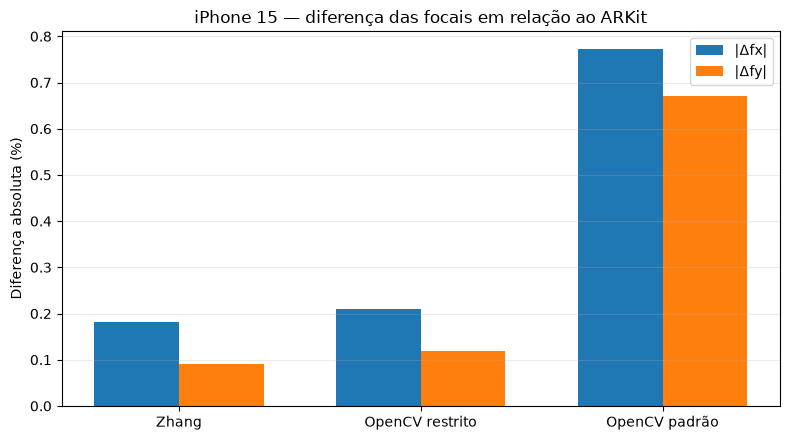

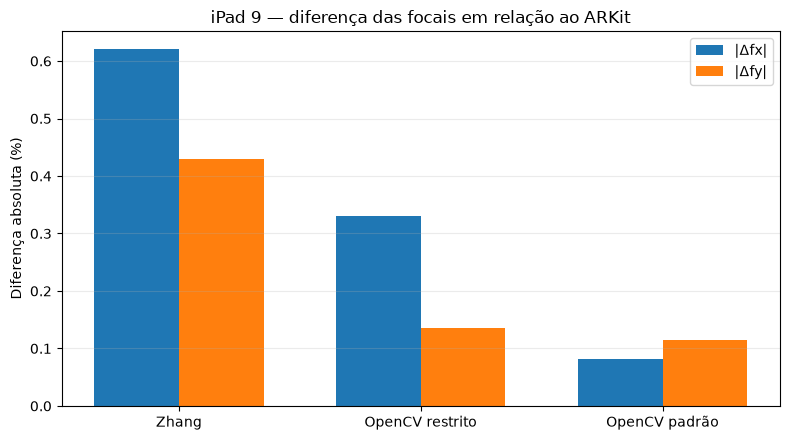

In [13]:
for camera_id, r in all_results.items():
    subset = comparison_df[comparison_df["camera_id"] == camera_id].copy()

    labels = subset["method"].tolist()
    x = np.arange(len(labels))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(x - width/2, subset["fx_abs_diff_pct"], width, label="|Δfx|")
    ax.bar(x + width/2, subset["fy_abs_diff_pct"], width, label="|Δfy|")

    ax.set_title(f"{r['label']} — diferença das focais em relação ao ARKit")
    ax.set_ylabel("Diferença absoluta (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 13. Verificação auxiliar das capturas high-resolution do ARKit

Esta seção **não entra na comparação principal**. Ela apenas verifica se o JSON contém amostras high-resolution e mostra suas estatísticas.

In [14]:
highres_rows = []

for camera_id, cfg in CAMERAS.items():
    data = load_json(resolved_paths[camera_id]["arkit"])
    stats = data.get("highResolutionStatistics")

    if stats is None:
        continue

    highres_rows.append({
        "camera": cfg["label"],
        "samples": stats.get("sampleCount"),
        "resolution": f"{stats.get('width')}x{stats.get('height')}",
        "fx_mean": stats.get("fxMean"),
        "fx_std": stats.get("fxStd"),
        "fy_mean": stats.get("fyMean"),
        "fy_std": stats.get("fyStd"),
        "cx_mean": stats.get("cxMean"),
        "cx_std": stats.get("cxStd"),
        "cy_mean": stats.get("cyMean"),
        "cy_std": stats.get("cyStd"),
    })

highres_df = pd.DataFrame(highres_rows)
display(highres_df)

,camera,samples,resolution,fx_mean,fx_std,fy_mean,fy_std,cx_mean,cx_std,cy_mean,cy_std
0,iPhone 15,5,4032x3024,3107.109082,1.249008,3107.109082,1.249008,2022.484277,0.317392,1517.714380,1.622499
1,iPad 9,5,1632x1224,1491.462769,11.534933,1491.462769,11.534933,815.433350,0.000000,611.433350,0.000000


## 14. Exportação opcional das tabelas consolidadas

As tabelas podem ser salvas em `results/comparison/` para uso direto no relatório.

In [15]:
EXPORT_TABLES = True

if EXPORT_TABLES:
    out_dir = RESULTS / "comparison"
    out_dir.mkdir(parents=True, exist_ok=True)

    transform_df.to_csv(out_dir / "arkit_transformations.csv", index=False)
    parameters_df.to_csv(out_dir / "intrinsic_parameters_all_methods.csv", index=False)
    comparison_df.to_csv(out_dir / "intrinsic_differences_vs_arkit.csv", index=False)
    stability_df.to_csv(out_dir / "arkit_temporal_stability.csv", index=False)

    print("Arquivos exportados para:", out_dir)

Arquivos exportados para: /Users/gabriellopesbastos/Projects/camera-calibration-zhang/results/comparison


## 15. Observações metodológicas para interpretação

- **Zhang** e **OpenCV restrito** são a comparação metodologicamente mais próxima, pois usam um modelo de distorção radial mais semelhante.
- O **OpenCV padrão** possui mais graus de liberdade no modelo de distorção e deve ser apresentado como comparação adicional.
- O **ARKit** é uma referência independente fornecida pelo sistema em outra resolução/orientação; por isso sua matriz precisa ser transformada antes da comparação.
- A rotação e a escala são operações geométricas determinísticas. O notebook registra os fatores usados para que o procedimento seja reproduzível.
- O skew $\gamma$ estimado por Zhang não deve ser comparado percentualmente ao ARKit, pois o valor de referência do ARKit é zero.
- As capturas high-resolution do ARKit são mantidas apenas como verificação auxiliar; a comparação principal usa os 120 frames do stream.